# 05 · Próxima melhor ação + IA generativa
[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jessicapmartins/previsao-faltas-consultas/blob/main/notebooks/05_proxima_melhor_acao.ipynb)

O modelo do notebook 03 diz **quem** tem mais risco de faltar. Falta decidir **o que fazer** com cada consulta. Este notebook:
1. mostra por que **não dá para medir o efeito do SMS** com esta base;
2. define uma **regra de custo** que escolhe, para cada consulta, a ação de menor custo esperado: nenhuma, lembrete automático, ligação, reconfirmação obrigatória ou encaixe (overbooking);
3. testa se a recomendação muda quando as premissas mudam;
4. usa um **LLM** para escrever os textos de lembrete e de ligação de cada ação, a partir só de perfis agregados.

É a mesma ideia de um *Next Best Action*: risco previsto + custo de cada ação → recomendação.

In [13]:
# Funções de apoio do projeto (mesma carga, mesmas variáveis e mesmo modelo em todos os notebooks)
import os, sys, urllib.request
try:
    import google.colab
    urllib.request.urlretrieve('https://raw.githubusercontent.com/jessicapmartins/previsao-faltas-consultas/main/src/apoio.py', '/content/apoio.py')
    sys.path.insert(0, '/content')
except ModuleNotFoundError:
    sys.path.insert(0, '../src')
import apoio, pandas as pd, numpy as np

con, DADOS, CSV = apoio.conectar()

def q(sql):
    """Roda uma consulta SQL no banco de consultas e devolve um DataFrame."""
    return pd.read_sql(sql, con)

apoio.garantir(con, CSV, 'previsoes')
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style='whitegrid')

Mounted at /content/drive


## 1. Limitação: o SMS não foi sorteado
No notebook 02, quem recebeu SMS faltou mais na base inteira, mas menos dentro de cada faixa de antecedência. O motivo é que o SMS **não foi distribuído ao acaso**: ele vai quase só para quem agendou com 3 dias ou mais, e quem agenda com antecedência falta mais. Sem sorteio (teste A/B), a diferença mistura o efeito do SMS com o efeito da antecedência e de outros fatores que não vemos.

**Por isso os efeitos das ações abaixo são premissas, não medições.**

In [14]:
q('''
SELECT CASE WHEN antecedencia_dias < 3 THEN '0 a 2 dias' ELSE '3 dias ou mais' END AS antecedencia,
       ROUND(100.0 * AVG(sms_recebido), 1)                          AS pct_com_sms,
       ROUND(100.0 * AVG(CASE WHEN sms_recebido = 1 THEN faltou END), 1) AS falta_com_sms_pct,
       ROUND(100.0 * AVG(CASE WHEN sms_recebido = 0 THEN faltou END), 1) AS falta_sem_sms_pct
FROM base_modelo GROUP BY 1
''')

,antecedencia,pct_com_sms,falta_com_sms_pct,falta_sem_sms_pct
0,0 a 2 dias,0.0,NaN,8.9
1,3 dias ou mais,59.1,27.6,32.7


**O que aprendi:** das consultas com até 2 dias de antecedência, nenhuma recebeu SMS (falta de 8,9%). Com 3 dias ou mais, 59,1% receberam SMS, e esse grupo faltou 27,6% contra 32,7% de quem não recebeu. A diferença é favorável ao SMS, mas não sabemos por que uns receberam e outros não. Sem sorteio, não dá para afirmar quanto do efeito é do SMS.

## 2. Premissas (ilustrativas, ajustáveis)
Custo de cada ação e quanto ela reduz a chance de falta. **Nenhum destes números foi medido nesta base.** Numa unidade real, eles viriam do financeiro (custo da consulta vaga, custo do minuto de atendente) e de um teste A/B (efeito de cada ação).

In [15]:
print(f'Custo de um horário vago: R$ {apoio.CUSTO_FALTA:.2f}')
print(f'Encaixe: chance de o encaixado comparecer = {apoio.ENCAIXE_COMPARECE:.0%}; custo se titular e encaixe vierem = R$ {apoio.CUSTO_SOBRECARGA:.2f}')
apoio.ACOES

Custo de um horário vago: R$ 100.00
Encaixe: chance de o encaixado comparecer = 80%; custo se titular e encaixe vierem = R$ 50.00


,acao,custo,reducao_falta
0,Nenhuma ação,0.00,0.00
1,Lembrete automático,0.25,0.10
2,Ligação de confirmação,3.00,0.25
3,Reconfirmação obrigatória,8.00,0.40


**A regra.** Para uma consulta com risco previsto *p* e um custo de horário vago *F*:
- ação com custo *c* e redução *r*: custo esperado = *c* + *p* × (1 − *r*) × *F*
- encaixe: custo esperado = *p* × *F* × (1 − chance de o encaixado vir) + (1 − *p*) × chance de o encaixado vir × custo de sobrecarga

A ação recomendada é a de **menor custo esperado**.

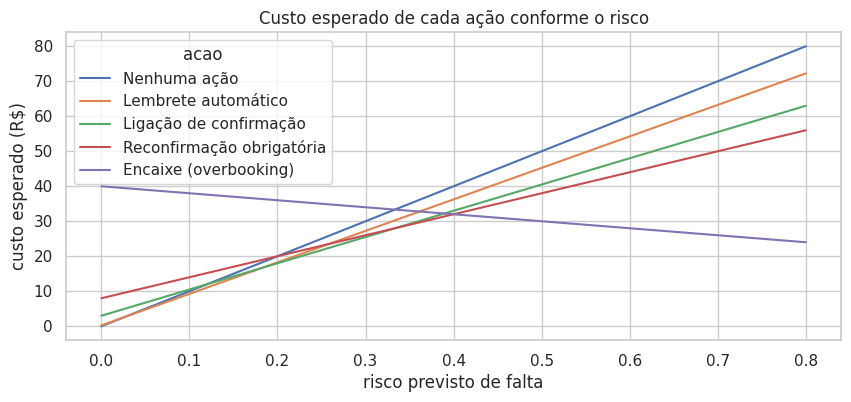

,min,max
acao,,
Nenhuma ação,0.000,0.025
Lembrete automático,0.030,0.180
Ligação de confirmação,0.185,0.330
Reconfirmação obrigatória,0.335,0.400
Encaixe (overbooking),0.405,0.800


In [16]:
riscos = np.linspace(0, 0.8, 161)
curvas = apoio.custos_esperados(riscos)
ax = curvas.set_index(riscos).plot(figsize=(10, 4))
ax.set_xlabel('risco previsto de falta'); ax.set_ylabel('custo esperado (R$)')
ax.set_title('Custo esperado de cada ação conforme o risco')
plt.show()

melhor = curvas.idxmin(axis=1)
faixas = pd.DataFrame({'risco': riscos, 'acao': melhor}).groupby('acao', sort=False)['risco'].agg(['min', 'max'])
faixas.round(3)

**O que aprendi:** com as premissas atuais, a regra recomenda: **nenhuma ação** até 2,5% de risco; **lembrete automático** de 3% a 18%; **ligação** de 18,5% a 33%; **reconfirmação obrigatória** de 33,5% a 40%; e **encaixe** acima de 40%. Quanto maior o risco, mais vale gastar com a ação.

## 3. Aplicar à agenda da semana de teste

In [17]:
previsoes = q('SELECT * FROM previsoes')
acoes = apoio.recomendar(previsoes)

resumo = acoes.groupby('acao').agg(consultas=('risco', 'size'), risco_medio=('risco', 'mean'),
                                   falta_real=('faltou', 'mean'))
resumo['pct_consultas'] = 100 * resumo['consultas'] / resumo['consultas'].sum()
ordem = ['Nenhuma ação', 'Lembrete automático', 'Ligação de confirmação', 'Reconfirmação obrigatória', 'Encaixe (overbooking)']
resumo = resumo.reindex([a for a in ordem if a in resumo.index])
resumo.round(3)

,consultas,risco_medio,falta_real,pct_consultas
acao,,,,
Nenhuma ação,2559,0.018,0.016,7.262
Lembrete automático,12142,0.074,0.064,34.455
Ligação de confirmação,12299,0.255,0.235,34.901
Reconfirmação obrigatória,3635,0.365,0.313,10.315
Encaixe (overbooking),4605,0.479,0.366,13.068


In [18]:
# Custo com o risco PREVISTO (o que a regra enxerga) e com as faltas REAIS da semana (checagem).
# Usar a falta real no lugar do risco mostra quanto a regra teria custado se as premissas de efeito valessem.
prev_c = apoio.custos_esperados(previsoes['risco'])
real_c = apoio.custos_esperados(previsoes['faltou'])
escolha = acoes['acao'].values
linha = lambda tab, col: tab[col].sum() if col else tab.values[np.arange(len(tab)), tab.columns.get_indexer(escolha)].sum()
cenarios = pd.DataFrame({
    'custo com o risco previsto (R$)': {n: linha(prev_c, c) for n, c in [
        ('Não fazer nada', 'Nenhuma ação'), ('Lembrete automático para todos', 'Lembrete automático'),
        ('Ligação para todos', 'Ligação de confirmação'), ('Regra de próxima melhor ação', None)]},
    'custo com as faltas reais (R$)': {n: linha(real_c, c) for n, c in [
        ('Não fazer nada', 'Nenhuma ação'), ('Lembrete automático para todos', 'Lembrete automático'),
        ('Ligação para todos', 'Ligação de confirmação'), ('Regra de próxima melhor ação', None)]},
})
cenarios['economia real x não fazer nada (%)'] = 100 * (1 - cenarios['custo com as faltas reais (R$)'] / cenarios.loc['Não fazer nada', 'custo com as faltas reais (R$)'])
cenarios.round(1)

,custo com o risco previsto (R$),custo com as faltas reais (R$),economia real x não fazer nada (%)
Não fazer nada,762154.5,653700.0,0.0
Lembrete automático para todos,694749.0,597140.0,8.7
Ligação para todos,677335.8,595995.0,8.8
Regra de próxima melhor ação,609920.2,578847.5,11.5


**O que aprendi:** na semana de teste (35.240 consultas), a regra distribui assim: lembrete 34,5%, ligação 34,9%, encaixe 13,1%, reconfirmação 10,3% e nenhuma ação 7,3%. Usando as **faltas reais** da semana, a regra custaria R$ 578,8 mil contra R$ 653,7 mil sem ação (**−11,5%**), melhor do que ligar para todos (−8,8%) ou mandar lembrete para todos (−8,7%), **se as premissas valerem**. O grupo de encaixe tinha 47,9% de risco previsto, mas faltou 36,6%: com o risco calibrado, parte dele iria para reconfirmação. É o custo da superestimação vista no notebook 03.

## 4. Sensibilidade: e se as premissas estiverem erradas?
Refazemos a regra com os efeitos das ações pela **metade** e **50% maiores**, e com o custo do horário vago em R$ 50 e R$ 150.

In [19]:
linhas = []
for fator in [0.5, 1.0, 1.5]:
    for custo in [50, 100, 150]:
        acoes_cen = apoio.ACOES.assign(reducao_falta=lambda d: d['reducao_falta'] * fator)
        r = apoio.recomendar(previsoes, custo_falta=custo, acoes=acoes_cen)
        dist = r['acao'].value_counts(normalize=True) * 100
        linhas.append({'efeito das ações': f'{fator:.0%}', 'custo do horário vago': custo,
                       'economia x não fazer nada (%)': 100 * (1 - r['custo_esperado_acao'].sum() / r['custo_esperado_sem_acao'].sum()),
                       **{a: dist.get(a, 0.0) for a in ordem}})
sens = pd.DataFrame(linhas).set_index(['efeito das ações', 'custo do horário vago'])
sens.round(1)

economia x não fazer nada (%)  \
efeito das ações custo do horário vago                                  
50%              50                                               4.7   
                 100                                             14.4   
                 150                                             25.3   
100%             50                                               9.7   
                 100                                             20.0   
                 150                                             29.8   
150%             50                                              18.8   
                 100                                             33.3   
                 150                                             41.6   

                                        Nenhuma ação  Lembrete automático  \
efeito das ações custo do horário vago                                      
50%              50                             32.2                 64.5   
                 100                            25.6                 53.1   
                 150                            14.2                 42.9   
100%             50                             25.6                 56.7   
                 100                             7.3                 34.5   
                 150                             2.3                 31.1   
150%             50                             14.2                 42.9   
                 100                             2.3                 31.1   
                 150                             1.0                 30.0   

                                        Ligação de confirmação  \
efeito das ações custo do horário vago                           
50%              50                                        0.0   
                 100                                       0.0   
                 150                                       4.1   
100%             50                                       15.6   
                 100                                      34.9   
                 150                                      18.0   
150%             50                                       35.0   
                 100                                      18.0   
                 150                                       4.5   

                                        Reconfirmação obrigatória  \
efeito das ações custo do horário vago                              
50%              50                                           0.0   
                 100                                          0.0   
                 150                                          0.0   
100%             50                                           0.0   
                 100                                         10.3   
                 150                                         22.8   
150%             50                                           7.5   
                 100                                         46.2   
                 150                                         57.6   

                                        Encaixe (overbooking)  
efeito das ações custo do horário vago                         
50%              50                                       3.3  
                 100                                     21.3  
                 150                                     38.8  
100%             50                                       2.0  
                 100                                     13.1  
                 150                                     25.9  
150%             50                                       0.4  
                 100                                      2.5  
                 150                                      6.8

**O que aprendi:** a economia (calculada com o risco previsto) vai de 4,7% a 41,6% conforme as premissas, e a **mistura de ações muda muito**: com efeitos pela metade, quase tudo vira lembrete ou encaixe; com efeitos 50% maiores, a reconfirmação passa a dominar. A lição: priorizar pelo risco é robusto, mas **qual ação usar depende de números que precisam ser medidos**.

## 5. IA generativa: textos de contato por ação
Para cada ação, montamos um **perfil agregado** das consultas que caíram nela (quantidade, risco médio, antecedência média, % que já faltou antes) e pedimos ao LLM:
- para lembrete automático: 2 mensagens de SMS/WhatsApp de até 160 caracteres;
- para ligação e reconfirmação: um roteiro curto para a atendente;
- para encaixe: orientações para a equipe de agenda.

**Dados e privacidade (LGPD):** o modelo recebe **só números agregados por grupo**. Nenhum identificador, bairro ou dado de saúde de paciente sai do notebook.

**Chave de API:** guarde em *Secrets* do Colab (ícone de chave na lateral) com o nome `GEMINI_API_KEY` e ative o acesso deste notebook. **Nunca** escreva a chave no notebook nem suba para o GitHub.

In [20]:
base = q('SELECT consulta_id, antecedencia_dias, faltas_anteriores, idade FROM base_modelo')
perfil = (acoes.merge(base, on='consulta_id')
               .groupby('acao').agg(consultas=('risco', 'size'), risco_medio=('risco', 'mean'),
                                    antecedencia_media=('antecedencia_dias', 'mean'),
                                    pct_ja_faltou=('faltas_anteriores', lambda s: 100 * (s > 0).mean()),
                                    idade_media=('idade', 'mean')))
perfil = perfil.drop(index='Nenhuma ação', errors='ignore').round(2)
perfil

,consultas,risco_medio,antecedencia_media,pct_ja_faltou,idade_media
acao,,,,,
Encaixe (overbooking),4605,0.48,24.18,51.66,28.56
Lembrete automático,12142,0.07,3.13,14.29,40.76
Ligação de confirmação,12299,0.26,13.89,13.30,40.07
Reconfirmação obrigatória,3635,0.36,20.90,22.61,27.35


In [21]:
PROMPT = """Você apoia a equipe de agendamento de uma rede pública de saúde no Brasil.
Grupo de consultas: {acao}.
Perfil agregado do grupo: {n} consultas; risco médio de falta previsto {risco:.0%};
agendadas em média com {antec:.0f} dias de antecedência; {ja:.0f}% dos pacientes já faltaram antes; idade média {idade:.0f} anos.

Tarefa: {tarefa}
Regras: tom acolhedor e claro; sempre ofereça a opção de remarcar ou cancelar para liberar a vaga;
não use nomes, dados pessoais ou de saúde; não prometa nada que a unidade possa não oferecer
(brindes, prioridade, multas). Se faltar informação para algo, deixe um campo entre colchetes, como [UNIDADE]."""

TAREFAS = {
    'Lembrete automático': 'escreva 2 versões de lembrete por SMS ou WhatsApp, com até 160 caracteres cada.',
    'Ligação de confirmação': 'escreva um roteiro de ligação de até 6 falas curtas para a atendente confirmar a presença.',
    'Reconfirmação obrigatória': 'escreva um roteiro de ligação de até 6 falas que peça a confirmação até 24 h antes e explique que, sem confirmação, a vaga vai para a fila de espera.',
    'Encaixe (overbooking)': 'escreva 3 orientações curtas para a equipe de agenda sobre como fazer encaixes nesses horários sem prejudicar quem comparecer.',
}

def montar_prompt(acao):
    p = perfil.loc[acao]
    return PROMPT.format(acao=acao, n=int(p['consultas']), risco=p['risco_medio'], antec=p['antecedencia_media'],
                         ja=p['pct_ja_faltou'], idade=p['idade_media'], tarefa=TAREFAS[acao])

print(montar_prompt(perfil.index[0]))                    # confira como o prompt ficou

Você apoia a equipe de agendamento de uma rede pública de saúde no Brasil.
Grupo de consultas: Encaixe (overbooking).
Perfil agregado do grupo: 4605 consultas; risco médio de falta previsto 48%;
agendadas em média com 24 dias de antecedência; 52% dos pacientes já faltaram antes; idade média 29 anos.

Tarefa: escreva 3 orientações curtas para a equipe de agenda sobre como fazer encaixes nesses horários sem prejudicar quem comparecer.
Regras: tom acolhedor e claro; sempre ofereça a opção de remarcar ou cancelar para liberar a vaga;
não use nomes, dados pessoais ou de saúde; não prometa nada que a unidade possa não oferecer
(brindes, prioridade, multas). Se faltar informação para algo, deixe um campo entre colchetes, como [UNIDADE].


In [22]:
MODELO = 'gemini-3.5-flash-lite'                         # se a Google trocar a versão, mude só aqui
try:
    from google.colab import userdata
    from google import genai                             # se der erro: !pip install -q -U google-genai
    cliente = genai.Client(api_key=userdata.get('GEMINI_API_KEY'))   # a chave vem do Secrets
    textos = []
    for acao in perfil.index:
        r = cliente.models.generate_content(model=MODELO, contents=montar_prompt(acao))
        textos.append({'acao': acao, 'texto': r.text})
        print('=' * 80, f'\n{acao}\n', '=' * 80); print(r.text)
    textos = pd.DataFrame(textos)
    textos.to_sql('textos_contato', con, if_exists='replace', index=False)
    textos.to_csv(f'{DADOS}/textos_contato.csv', index=False)
except ModuleNotFoundError:
    print('Fora do Colab: a geração de textos foi pulada. Rode este notebook no Colab com a chave no Secrets.')

Encaixe (overbooking)
Olá, equipe! Para lidarmos com os encaixes da melhor forma, cuidando de quem comparece e mantendo nossa organização, seguem três orientações importantes:

1. **Confirme a presença com carinho e antecedência:** Como este grupo tem um perfil com maior histórico de faltas e antecedência maior, entre em contato próximo à data para confirmar a vinda. Aproveite para perguntar se o paciente ainda precisa da consulta e reforce que, caso não possa comparecer, **ofereça sempre a opção de remarcar ou cancelar para liberar a vaga** para outra pessoa que precisa na [UNIDADE].

2. **Organize o fluxo de atendimento:** Como trabalhamos com margem de encaixe, prepare a sala de espera e comunique a equipe de atendimento na [UNIDADE] para acolher os pacientes com paciência, explicando que, devido à dinâmica do dia, pode haver variação no tempo de espera, mantendo sempre um atendimento humanizado.

3. **Gerencie as expectativas sem promessas indevidas:** Ao receber o paciente encaixa

**Revisão humana dos textos** :
Limite de 160 caracteres e opção de remarcar: os dois lembretes respeitam o limite com os campos entre colchetes (148 e 152 caracteres) e oferecem remarcar ou cancelar. Com o nome real da unidade, podem passar de 160 e precisam ser encurtados.
Promessas e fatos inventados: o roteiro de reconfirmação afirma que há “uma fila de espera grande para essa especialidade” e que a vaga “estará garantida”, informações que não estavam no prompt. O roteiro de ligação pede documento com foto e cartão do SUS, o que precisa ser confirmado com a unidade.
Perfil do grupo: no roteiro de reconfirmação, o modelo descreveu o grupo como “agendamento prévio de 3 dias”, mas a antecedência média desse grupo é de 21 dias. Ele misturou com o perfil do grupo de lembrete.
Tom: acolhedor e claro em todos os textos; as orientações de encaixe tratam bem o tempo de espera.

Conclusão: os textos são um bom rascunho e economizam tempo, mas não podem ir direto para os pacientes. Antes de usar, é preciso revisar os fatos e as promessas e testar o tamanho final das mensagens.

## 6. Salvar as recomendações

In [23]:
acoes.to_sql('acoes', con, if_exists='replace', index=False)
q('SELECT acao, COUNT(*) AS consultas FROM acoes GROUP BY acao ORDER BY consultas DESC')

,acao,consultas
0,Ligação de confirmação,12299
1,Lembrete automático,12142
2,Encaixe (overbooking),4605
3,Reconfirmação obrigatória,3635
4,Nenhuma ação,2559


## Conclusão e próximos passos
A regra transforma o risco do modelo em uma **ação concreta para cada consulta**, com o custo de cada escolha explícito. É a lógica de um Next Best Action, aplicada à agenda de uma rede de saúde. Ela ainda não está pronta para uso real, por três motivos:
1. **Os efeitos das ações são premissas.** O próximo passo é um teste A/B: sortear consultas de risco médio entre nenhuma ação, lembrete e ligação por algumas semanas e medir a falta em cada grupo.
2. **O risco precisa de recalibração**, para não mandar para encaixe quem não tem tanto risco.
3. **Encaixe em saúde pública tem custo humano** (espera, sobrecarga da equipe). Só faz sentido com fila de espera ativa e limite de encaixes por turno.

Falta também incluir a **capacidade da equipe** (quantas ligações por dia cabem) como restrição da regra.

## Gravar no Google Drive
Fecha o banco e força o Drive a gravar agora. Sem isso, o próximo notebook pode não enxergar as tabelas novas.

In [12]:
con.commit()
con.close()
try:
    from google.colab import drive
    drive.flush_and_unmount()
    print('Banco gravado no Google Drive.')
except ModuleNotFoundError:
    print('Fora do Colab: nada a sincronizar.')

Banco gravado no Google Drive.
